In [57]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, SelectKBest, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import QuantileTransformer
from sklearn.svm import SVC
from tqdm import tqdm

warnings.filterwarnings("ignore")

#Input Data
df = pd.read_csv("bl_progression_data (3).csv")
sub_data = df[df["BASELINE_DX"].isin(["EMCI", "LMCI"])].copy()

#Drop Columns
exclude_cols = [
    "RID",
    "VISCODE",
    "BASELINE_DX",
    "FINAL_DX",
    "PROGRESSION_MONTH",
    "PROGRESSED",
    "TOTAL_VISITS",
    "DX",
    "DX_bl",
    "COLPROT",
    "ORIGPROT",
]
metabolite_cols = [c for c in sub_data.columns if c not in exclude_cols]

X = sub_data[metabolite_cols].to_numpy()
y = (sub_data["BASELINE_DX"] == "LMCI").astype(int).to_numpy()

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)


#Create benchmark functions
def run_filter_benchmark(filter_type):
  accs, f1s, aurocs = [], [], []  
  for train_idx, val_idx in tqdm(rskf.split(X, y), desc=f"Filter: {filter_type}"):
    X_tr, X_va = X[train_idx], X[val_idx]
    y_tr, y_va = y[train_idx], y[val_idx]

    scaler = QuantileTransformer(output_distribution="normal", random_state=42)
    X_tr_sc = scaler.fit_transform(X_tr)
    X_va_sc = scaler.transform(X_va)

    # Filter Selection Methods
    if filter_type == "f_classif":
      selector = SelectKBest(score_func=f_classif, k=30)
      X_tr_k = selector.fit_transform(X_tr_sc, y_tr)
      X_va_k = selector.transform(X_va_sc)
    elif filter_type == "MI":
      selector = SelectKBest(
          score_func=lambda x_in, y_in: mutual_info_classif(
              x_in, y_in, random_state=42
          ),
          k=30,
      )
      X_tr_k = selector.fit_transform(X_tr_sc, y_tr)
      X_va_k = selector.transform(X_va_sc)
    elif filter_type == "SBSFP":
      scores = [
          balanced_accuracy_score(
              y_tr, (X_tr_sc[:, i] > np.median(X_tr_sc[:, i])).astype(int)
          )
          for i in range(X_tr_sc.shape[1])
      ]
      top30 = np.argsort(scores)[-30:]
      X_tr_k = X_tr_sc[:, top30]
      X_va_k = X_va_sc[:, top30]
    elif filter_type == "SCS":
      corr_matrix = np.abs(np.corrcoef(X_tr_sc.T))
      keep = list(range(X_tr_sc.shape[1]))
      for i in range(X_tr_sc.shape[1]):
        if i not in keep:
          continue
        for j in range(i + 1, X_tr_sc.shape[1]):
          if j in keep and corr_matrix[i, j] > 0.8:
            keep.remove(j)
      X_tr_uncorr = X_tr_sc[:, keep]
      X_va_uncorr = X_va_sc[:, keep]
      k_sel = min(30, len(keep))
      selector = SelectKBest(
          score_func=lambda x_in, y_in: mutual_info_classif(
              x_in, y_in, random_state=42
          ),
          k=k_sel,
      )
      X_tr_k = selector.fit_transform(X_tr_uncorr, y_tr)
      X_va_k = selector.transform(X_va_uncorr)

    # LR-RFE
    log_reg = LogisticRegression(
        penalty="l1", solver="liblinear", random_state=42
    )
    rfe = RFE(log_reg, n_features_to_select=min(8, X_tr_k.shape[1]))
    X_tr_rfe = rfe.fit_transform(X_tr_k, y_tr)
    X_va_rfe = rfe.transform(X_va_k)

    # Fit Classifier on RFE selected feat
    rf = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
    )
    rf.fit(X_tr_rfe, y_tr)
    y_pred = rf.predict(X_va_rfe)  
    y_prob = rf.predict_proba(X_va_rfe)[:, 1]

    accs.append(balanced_accuracy_score(y_va, y_pred))
    f1s.append(f1_score(y_va, y_pred, average="binary"))
    aurocs.append(roc_auc_score(y_va, y_prob))
    #return performance
  return (
      np.mean(accs),
      np.std(accs),
      np.mean(f1s),
      np.std(f1s),
      np.mean(aurocs),
      np.std(aurocs),
  )


print("Running Filter Benchmark...")
filter_names = ["f_classif", "SBSFP", "SCS", "MI"]
filter_res = {fn: run_filter_benchmark(fn) for fn in filter_names}
df_filters = pd.DataFrame([
    {
        "Filter": k,
        "Accuracy": round(v[0], 3),
        "Acc_SD": round(v[1], 3),
        "F1": round(v[2], 3),
        "F1_SD": round(v[3], 3),
        "AUROC": round(v[4], 3),
        "AUC_SD": round(v[5], 3),
    }
    for k, v in filter_res.items()
])


plt.figure(figsize=(8, 5))
x_axis = np.arange(len(df_filters))
plt.bar(
    x_axis - 0.2,
    df_filters["Accuracy"],
    0.4,
    label="CV Accuracy",
    capsize=5,
    color="#4C72B0",
)
plt.bar(
    x_axis + 0.2,
    df_filters["F1"],
    0.4,
    label="CV F1",
    capsize=5,
    color="#DD8452",
)

for i in range(len(df_filters)):
  plt.text(
      i - 0.2,
      df_filters["Accuracy"][i] + df_filters["Acc_SD"][i] + 0.01,
      f"{df_filters['Accuracy'][i]:.3f}",
      ha="center",
      fontsize=9,
  )
  plt.text(
      i + 0.2,
      df_filters["F1"][i] + df_filters["F1_SD"][i] + 0.01,
      f"{df_filters['F1'][i]:.3f}",
      ha="center",
      fontsize=9,
  )

plt.xticks(x_axis, df_filters["Filter"])  
plt.ylim(0.65, 0.92)
plt.ylabel("Score")
plt.title("Figure 2: Feature Filter Benchmarking (50-Fold Leak-Free CV)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figure2_filter_benchmarking.png", dpi=300)
plt.close()


#Run benchmark again, this time comparing clf's instead of filters
def run_classifier_benchmark(clf_type):
  accs, f1s, aurocs = [], [], []
  for train_idx, val_idx in tqdm(rskf.split(X, y), desc=f"CLF: {clf_type}"):
    X_tr, X_va = X[train_idx], X[val_idx]
    y_tr, y_va = y[train_idx], y[val_idx]

    scaler = QuantileTransformer(output_distribution="normal", random_state=42)
    X_tr_sc = scaler.fit_transform(X_tr)
    X_va_sc = scaler.transform(X_va)

    selector = SelectKBest(
        score_func=lambda x_in, y_in: mutual_info_classif(
            x_in, y_in, random_state=42
        ),
        k=30,
    )
    X_tr_k = selector.fit_transform(X_tr_sc, y_tr)
    X_va_k = selector.transform(X_va_sc)

    log_reg = LogisticRegression(
        penalty="l1", solver="liblinear", random_state=42
    )
    rfe = RFE(log_reg, n_features_to_select=8)
    X_tr_rfe = rfe.fit_transform(X_tr_k, y_tr)
    X_va_rfe = rfe.transform(X_va_k)

    if clf_type == "KNN":
      model = KNeighborsClassifier(n_neighbors=7)
    elif clf_type == "SVM":
      model = SVC(
          kernel="rbf",
          C=1.0,
          probability=True,
          class_weight="balanced",
          random_state=42,
      )
    elif clf_type == "LR":
      model = LogisticRegression(
          penalty="l2", C=1.0, class_weight="balanced", random_state=42
      )
    elif clf_type == "RF":
      model = RandomForestClassifier(
          n_estimators=300,
          max_depth=8,
          min_samples_split=5,
          min_samples_leaf=2,
          max_features="sqrt",
          class_weight="balanced",
          random_state=42,
      )

    model.fit(X_tr_rfe, y_tr)
    y_pred = model.predict(X_va_rfe)
    y_prob = (
        model.predict_proba(X_va_rfe)[:, 1]
        if hasattr(model, "predict_proba")
        else y_pred
    )

    accs.append(balanced_accuracy_score(y_va, y_pred))
    f1s.append(f1_score(y_va, y_pred, average="binary"))
    aurocs.append(roc_auc_score(y_va, y_prob))

  return (
      np.mean(accs),
      np.std(accs),
      np.mean(f1s),
      np.std(f1s),
      np.mean(aurocs),
      np.std(aurocs),
  )


print("Running Classifier Benchmark...")
clf_names = ["KNN", "SVM", "LR", "RF"]
clf_res = {cn: run_classifier_benchmark(cn) for cn in clf_names}
df_clfs = pd.DataFrame([
    {
        "Classifier": k,
        "Accuracy": round(v[0], 3),
        "Acc_SD": round(v[1], 3),
        "F1": round(v[2], 3),
        "F1_SD": round(v[3], 3),
        "AUROC": round(v[4], 3),
        "AUC_SD": round(v[5], 3),
    }
    for k, v in clf_res.items()
])

# Plot Figure 3
plt.figure(figsize=(8, 5))
x_axis = np.arange(len(df_clfs))
plt.bar(
    x_axis - 0.2,
    df_clfs["AUROC"],
    0.4,
    yerr=df_clfs["AUC_SD"],
    label="CV AUROC",
    capsize=5,
    color="#4C72B0",
)
plt.bar(
    x_axis + 0.2,
    df_clfs["F1"],
    0.4,
    yerr=df_clfs["F1_SD"],
    label="CV F1",
    capsize=5,
    color="#DD8452",
)

for i in range(len(df_clfs)):
  plt.text(
      i - 0.2,
      df_clfs["AUROC"][i] + df_clfs["AUC_SD"][i] + 0.01,
      f"{df_clfs['AUROC'][i]:.3f}",
      ha="center",
      fontsize=9,
  )  
  plt.text(
      i + 0.2,
      df_clfs["F1"][i] + df_clfs["F1_SD"][i] + 0.01,
      f"{df_clfs['F1'][i]:.3f}",
      ha="center",
      fontsize=9,
  )

plt.xticks(x_axis, df_clfs["Classifier"])
plt.ylim(0.65, 0.92)
plt.ylabel("Score")
plt.title("Figure 3: Classifier Benchmarking (50-Fold Leak-Free CV)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figure3_classifier_benchmarking.png", dpi=300)
plt.close()

print("Benchmarking script executed successfully. Figures saved as PNGs.")

Running Filter Benchmark...


Filter: f_classif: 50it [01:26,  1.74s/it]
Filter: SBSFP: 50it [01:56,  2.32s/it]
Filter: SCS: 50it [02:02,  2.45s/it]
Filter: MI: 50it [02:02,  2.46s/it]


Running Classifier Benchmark...


CLF: KNN: 50it [01:00,  1.22s/it]
CLF: SVM: 50it [01:01,  1.23s/it]
CLF: LR: 50it [01:01,  1.23s/it]
CLF: RF: 50it [02:01,  2.42s/it]


Benchmarking script executed successfully. Figures saved as PNGs.


In [60]:
df_filters

,Filter,Accuracy,Acc_SD,F1,F1_SD,AUROC,AUC_SD
0,f_classif,0.790,0.029,0.831,0.025,0.869,0.024
1,SBSFP,0.750,0.037,0.802,0.030,0.815,0.036
2,SCS,0.797,0.031,0.836,0.023,0.877,0.025
3,MI,0.799,0.032,0.837,0.023,0.879,0.023


In [58]:
df_clfs

,Classifier,Accuracy,Acc_SD,F1,F1_SD,AUROC,AUC_SD
0,KNN,0.750,0.033,0.829,0.027,0.850,0.030
1,SVM,0.808,0.030,0.835,0.026,0.871,0.023
2,LR,0.773,0.031,0.814,0.025,0.850,0.027
3,RF,0.799,0.032,0.837,0.023,0.879,0.023


In [6]:
import pandas as pd
import numpy as np
import warnings
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import QuantileTransformer
from sklearn.feature_selection import SelectKBest, mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, matthews_corrcoef, confusion_matrix, brier_score_loss
)

warnings.filterwarnings("ignore")


def compute_nogueira_index(selection_matrix):

    M, d = selection_matrix.shape
    p_hat = selection_matrix.mean(axis=0)
    k_bar = p_hat.sum()
    
    if k_bar == 0 or k_bar == d:
        return 0.0
        
    s2 = selection_matrix.var(axis=0, ddof=1).sum()
    phi = 1.0 - (s2 / ((k_bar / d) * (1.0 - k_bar / d) * d))
    return phi


def run_leak_free_pipeline(df_input, group_a, group_b, metabolite_cols, n_splits=5, n_repeats=10, random_state=42):
    # Filter dataset for comparison pair
    sub_data = df_input[df_input["BASELINE_DX"].isin([group_a, group_b])].copy()
    X = sub_data[metabolite_cols].to_numpy()
    y = (sub_data["BASELINE_DX"] == group_b).astype(int).to_numpy() # positive class: group_b
    
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=random_state)
    
    y_trues, y_preds, y_probs = [], [], []
    total_folds = n_splits * n_repeats
    selection_matrix = np.zeros((total_folds, len(metabolite_cols)), dtype=int)
    
    fold_idx = 0
    for train_idx, val_idx in rskf.split(X, y):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]
        
        # Guard against zero variance in small subsets
        if len(np.unique(y_train)) < 2:
            continue
            
        # Scaling
        scaler = QuantileTransformer(output_distribution="normal", random_state=random_state)
        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)
        
        # Step 1: MI
        def custom_MI(x_in, y_in):
            return mutual_info_classif(x_in, y_in, random_state=random_state)
            
        selector_mi = SelectKBest(score_func=custom_MI, k=30)
        X_train_mi = selector_mi.fit_transform(X_train_scaled, y_train)
        mi_support_indices = selector_mi.get_support(indices=True)
        
        # Step 2: LR-RFE
        log_reg = LogisticRegression(penalty="l1", solver="liblinear", random_state=random_state)
        rfe = RFE(log_reg, n_features_to_select=8)
        X_train_rfe = rfe.fit_transform(X_train_mi, y_train)
        

        selected_subset_indices = mi_support_indices[rfe.support_]
        selection_matrix[fold_idx, selected_subset_indices] = 1
        
        # Step 3: RF on selected feat.
        rf = RandomForestClassifier(
            n_estimators=300,
            max_depth=8,
            min_samples_split=5,
            min_samples_leaf=2,
            max_features="sqrt",
            class_weight="balanced",
            random_state=random_state
        )
        rf.fit(X_train_rfe, y_train)
        
        # Out-of-fold Validation
        X_val_mi = selector_mi.transform(X_val_scaled)
        X_val_rfe = rfe.transform(X_val_mi)
        
        y_pred = rf.predict(X_val_rfe)
        y_prob = rf.predict_proba(X_val_rfe)[:, 1]
        
        y_trues.extend(y_val)
        y_preds.extend(y_pred)
        y_probs.extend(y_prob)
        
        fold_idx += 1
        
    y_trues = np.array(y_trues)
    y_preds = np.array(y_preds)
    y_probs = np.array(y_probs)
    
    # Calculate Performance Metrics
    acc = accuracy_score(y_trues, y_preds)
    sens = recall_score(y_trues, y_preds)
    cm = confusion_matrix(y_trues, y_preds)
    spec = cm[0,0] / (cm[0,0] + cm[0,1]) if (cm[0,0] + cm[0,1]) > 0 else 0.0
    bal_acc = (sens + spec) / 2.0
    f1 = f1_score(y_trues, y_preds, average='macro')
    mcc = matthews_corrcoef(y_trues, y_preds)
    auc = roc_auc_score(y_trues, y_probs)
    brier = brier_score_loss(y_trues, y_probs)

    phi = compute_nogueira_index(selection_matrix)
    
    # Selection Frequencies for Top Panel Members
    freqs = selection_matrix.mean(axis=0) * 100.0
    top_features = sorted(list(zip(metabolite_cols, freqs)), key=lambda x: x[1], reverse=True)
    
    results = {
        'Comparison': f"{group_a} vs {group_b}",
        'N_total': len(y),
        'Class_Counts': f"{group_a}: {(y==0).sum()}, {group_b}: {(y==1).sum()}",
        'AUROC': round(auc, 3),
        'Bal_Acc': round(bal_acc, 3),
        'Accuracy': round(acc, 3),
        'Sensitivity': round(sens, 3),
        'Specificity': round(spec, 3),
        'Macro_F1': round(f1, 3),
        'MCC': round(mcc, 3),
        'Brier_Score': round(brier, 3),
        'Nogueira_Phi': round(phi, 3),
        'Top_8_Panel': [f[0] for f in top_features[:8]],
        'Top_8_Freqs': [round(f[1], 1) for f in top_features[:8]]
    }
    return results, selection_matrix, top_features


df = pd.read_csv("bl_progression_data (3).csv")
exclude_cols = ['RID','VISCODE','BASELINE_DX','FINAL_DX','PROGRESSION_MONTH','PROGRESSED','TOTAL_VISITS','DX','DX_bl','COLPROT','ORIGPROT']
metabolite_cols = [c for c in df.columns if c not in exclude_cols]

continuum_pairs = [
    ("CN", "Dementia"),    
    ("CN", "EMCI"),        
    ("EMCI", "LMCI"),      
    ("LMCI", "Dementia")  
]

all_results = []
top_panels_dict = {}

for g_a, g_b in continuum_pairs:
    res, _, top_feats = run_leak_free_pipeline(df, g_a, g_b, metabolite_cols)
    all_results.append(res)
    top_panels_dict[f"{g_a}_vs_{g_b}"] = pd.DataFrame(top_feats[:8], columns=['Metabolite', 'Selection Frequency (%)'])


df_summary = pd.DataFrame(all_results)
summary_cols = ['Comparison', 'N_total', 'Class_Counts', 'AUROC', 'Bal_Acc', 'Accuracy', 'Sensitivity', 'Specificity', 'Macro_F1', 'MCC', 'Nogueira_Phi']
print("=== Benchmark Performance Across the Disease Continuum ===")
print(df_summary[summary_cols].to_string(index=False))

print("\n=== Primary EMCI vs. LMCI Consensus Panel ===")
print(top_panels_dict["EMCI_vs_LMCI"].to_string(index=False))

# Export summary tables to CSV
df_summary[summary_cols].to_csv("continuum_benchmark_results.csv", index=False)
top_panels_dict["EMCI_vs_LMCI"].to_csv("leakfree_top8_EMCI_vs_LMCI.csv", index=False)

=== Benchmark Performance Across the Disease Continuum ===
      Comparison  N_total             Class_Counts  AUROC  Bal_Acc  Accuracy  Sensitivity  Specificity  Macro_F1   MCC  Nogueira_Phi
  CN vs Dementia      536   CN: 350, Dementia: 186  0.669    0.620     0.650        0.524        0.717     0.618 0.237         0.407
      CN vs EMCI      572       CN: 350, EMCI: 222  0.773    0.682     0.695        0.626        0.739     0.681 0.363         0.498
    EMCI vs LMCI      643     EMCI: 222, LMCI: 421  0.878    0.799     0.797        0.794        0.805     0.785 0.578         0.723
LMCI vs Dementia      607 LMCI: 421, Dementia: 186  0.550    0.542     0.601        0.390        0.695     0.541 0.083         0.175

=== Primary EMCI vs. LMCI Consensus Panel (Leak-Free 50-Fold CV) ===
               Metabolite  Selection Frequency (%)
            GLYCERIC_ACID                    100.0
                     C8_0                    100.0
                  X3_DHCA                    100.0
  

In [2]:
import warnings
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import QuantileTransformer

warnings.filterwarnings("ignore")


def compute_nogueira_index(selection_matrix):

  M, d = selection_matrix.shape
  p_hat = selection_matrix.mean(axis=0)
  k_bar = p_hat.sum()

  if k_bar == 0 or k_bar == d:
    return 0.0

  s2 = selection_matrix.var(axis=0, ddof=1).sum()
  phi = 1.0 - (s2 / ((k_bar / d) * (1.0 - k_bar / d) * d))
  return phi


def run_leak_free_pipeline(
    df_input,
    group_a,
    group_b,
    metabolite_cols,
    n_splits=5,
    n_repeats=10,
    random_state=42,
    n_bootstraps=1000, 
):

  sub_data = df_input[df_input["BASELINE_DX"].isin([group_a, group_b])].copy()
  X = sub_data[metabolite_cols].to_numpy()
  y = (sub_data["BASELINE_DX"] == group_b).astype(int).to_numpy()

  rskf = RepeatedStratifiedKFold(
      n_splits=n_splits, n_repeats=n_repeats, random_state=random_state
  )

  y_trues, y_preds, y_probs = [], [], []
  total_folds = n_splits * n_repeats
  selection_matrix = np.zeros((total_folds, len(metabolite_cols)), dtype=int)

  fold_idx = 0
  for train_idx, val_idx in rskf.split(X, y):
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    if len(np.unique(y_train)) < 2:
      continue


    scaler = QuantileTransformer(
        output_distribution="normal", random_state=random_state
    )
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)


    def custom_MI(x_in, y_in):
      return mutual_info_classif(x_in, y_in, random_state=random_state)

    selector_mi = SelectKBest(score_func=custom_MI, k=30)
    X_train_mi = selector_mi.fit_transform(X_train_scaled, y_train)
    mi_support_indices = selector_mi.get_support(indices=True)


    log_reg = LogisticRegression(
        penalty="l1", solver="liblinear", random_state=random_state
    )
    rfe = RFE(log_reg, n_features_to_select=8)
    X_train_rfe = rfe.fit_transform(X_train_mi, y_train)


    selected_subset_indices = mi_support_indices[rfe.support_]
    selection_matrix[fold_idx, selected_subset_indices] = 1


    rf = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        random_state=random_state,
    )
    rf.fit(X_train_rfe, y_train)


    X_val_mi = selector_mi.transform(X_val_scaled)
    X_val_rfe = rfe.transform(X_val_mi)

    y_pred = rf.predict(X_val_rfe)
    y_prob = rf.predict_proba(X_val_rfe)[:, 1]

    y_trues.extend(y_val)
    y_preds.extend(y_pred)
    y_probs.extend(y_prob)

    fold_idx += 1

  y_trues = np.array(y_trues)
  y_preds = np.array(y_preds)
  y_probs = np.array(y_probs)


  acc = accuracy_score(y_trues, y_preds)
  sens = recall_score(y_trues, y_preds)
  cm = confusion_matrix(y_trues, y_preds)
  spec = cm[0, 0] / (cm[0, 0] + cm[0, 1]) if (cm[0, 0] + cm[0, 1]) > 0 else 0.0
  bal_acc = (sens + spec) / 2.0
  f1 = f1_score(y_trues, y_preds, average="macro")
  mcc = matthews_corrcoef(y_trues, y_preds)
  auc = roc_auc_score(y_trues, y_probs)
  brier = brier_score_loss(y_trues, y_probs)

  # Bootstrap 95% Confidence Intervals
  np.random.seed(random_state)
  n_samples = len(y_trues)
  boot_aucs, boot_bal_accs, boot_accs = [], [], []

  for _ in range(n_bootstraps):
    boot_idx = np.random.choice(n_samples, size=n_samples, replace=True)
    y_t_b, y_p_b, y_prob_b = (
        y_trues[boot_idx],
        y_preds[boot_idx],
        y_probs[boot_idx],
    )

    if len(np.unique(y_t_b)) < 2:
      continue

    boot_aucs.append(roc_auc_score(y_t_b, y_prob_b))
    boot_accs.append(accuracy_score(y_t_b, y_p_b))

    cm_b = confusion_matrix(y_t_b, y_p_b)
    sens_b = recall_score(y_t_b, y_p_b)
    spec_b = (
        cm_b[0, 0] / (cm_b[0, 0] + cm_b[0, 1])
        if (cm_b[0, 0] + cm_b[0, 1]) > 0
        else 0.0
    )
    boot_bal_accs.append((sens_b + spec_b) / 2.0)

  auc_ci = f"{round(auc, 3)} ({round(np.percentile(boot_aucs, 2.5), 3)}–{round(np.percentile(boot_aucs, 97.5), 3)})"
  bal_acc_ci = f"{round(bal_acc, 3)} ({round(np.percentile(boot_bal_accs, 2.5), 3)}–{round(np.percentile(boot_bal_accs, 97.5), 3)})"
  acc_ci = f"{round(acc, 3)} ({round(np.percentile(boot_accs, 2.5), 3)}–{round(np.percentile(boot_accs, 97.5), 3)})"

  # Nogeuira Index
  phi = compute_nogueira_index(selection_matrix)

  # Selection Frequencies 
  freqs = selection_matrix.mean(axis=0) * 100.0
  top_features = sorted(
      list(zip(metabolite_cols, freqs)), key=lambda x: x[1], reverse=True
  )

  results = {
      "Comparison": f"{group_a} vs {group_b}",
      "N_total": len(y),
      "Class_Counts": f"{group_a}: {(y==0).sum()}, {group_b}: {(y==1).sum()}",
      "AUROC (95% CI)": auc_ci,
      "Bal_Acc (95% CI)": bal_acc_ci,
      "Accuracy (95% CI)": acc_ci,
      "Sensitivity": round(sens, 3),
      "Specificity": round(spec, 3),
      "Macro_F1": round(f1, 3),
      "MCC": round(mcc, 3),
      "Brier_Score": round(brier, 3),
      "Nogueira_Phi": round(phi, 3),
      "Top_8_Panel": [f[0] for f in top_features[:8]],
      "Top_8_Freqs": [round(f[1], 1) for f in top_features[:8]],
  }
  return results, selection_matrix, top_features



df = pd.read_csv("bl_progression_data (3).csv")
exclude_cols = [
    "RID",
    "VISCODE",
    "BASELINE_DX",
    "FINAL_DX",
    "PROGRESSION_MONTH",
    "PROGRESSED",
    "TOTAL_VISITS",
    "DX",
    "DX_bl",
    "COLPROT",
    "ORIGPROT",
]
metabolite_cols = [c for c in df.columns if c not in exclude_cols]

continuum_pairs = [
    ("CN", "Dementia"), 
    ("CN", "EMCI"),  
    ("EMCI", "LMCI"), 
    ("LMCI", "Dementia"),  ]

all_results = []
top_panels_dict = {}

for g_a, g_b in continuum_pairs:
  res, _, top_feats = run_leak_free_pipeline(df, g_a, g_b, metabolite_cols)
  all_results.append(res)
  top_panels_dict[f"{g_a}_vs_{g_b}"] = pd.DataFrame(
      top_feats[:8], columns=["Metabolite", "Selection Frequency (%)"]
  )


df_summary = pd.DataFrame(all_results)
summary_cols = [
    "Comparison",
    "N_total",
    "Class_Counts",
    "AUROC (95% CI)",
    "Bal_Acc (95% CI)",
    "Accuracy (95% CI)",
    "Sensitivity",
    "Specificity",
    "Macro_F1",
    "MCC",
    "Nogueira_Phi",
]

print("=== Benchmark Performance Across the Disease Continuum ===")
print(df_summary[summary_cols].to_string(index=False))

print("\n=== Primary EMCI vs. LMCI Consensus Panel ===")
print(top_panels_dict["EMCI_vs_LMCI"].to_string(index=False))

# Export summary tables to CSV
df_summary[summary_cols].to_csv("continuum_benchmark_results.csv", index=False)
top_panels_dict["EMCI_vs_LMCI"].to_csv(
    "new_top8_EMCI_vs_LMCI.csv", index=False
)

=== Benchmark Performance Across the Disease Continuum ===
      Comparison  N_total             Class_Counts      AUROC (95% CI)   Bal_Acc (95% CI)   Accuracy (95% CI)  Sensitivity  Specificity  Macro_F1   MCC  Nogueira_Phi
  CN vs Dementia      536   CN: 350, Dementia: 186 0.669 (0.654–0.683) 0.62 (0.606–0.633)  0.65 (0.636–0.662)        0.524        0.717     0.618 0.237         0.407
      CN vs EMCI      572       CN: 350, EMCI: 222 0.773 (0.762–0.786) 0.682 (0.67–0.695) 0.695 (0.684–0.707)        0.626        0.739     0.681 0.363         0.498
    EMCI vs LMCI      643     EMCI: 222, LMCI: 421 0.878 (0.869–0.887) 0.799 (0.789–0.81) 0.797 (0.788–0.808)        0.794        0.805     0.785 0.578         0.723
LMCI vs Dementia      607 LMCI: 421, Dementia: 186  0.55 (0.533–0.565) 0.542 (0.53–0.555)  0.601 (0.59–0.614)        0.390        0.695     0.541 0.083         0.175

=== Primary EMCI vs. LMCI Consensus Panel ===
               Metabolite  Selection Frequency (%)
            G

In [62]:
df_summary[summary_cols]

,Comparison,N_total,Class_Counts,AUROC (95% CI),Bal_Acc (95% CI),Accuracy (95% CI),Sensitivity,Specificity,Macro_F1,MCC,Nogueira_Phi
0,CN vs Dementia,536,"CN: 350, Dementia: 186",0.669 (0.654–0.683),0.62 (0.606–0.633),0.65 (0.636–0.662),0.524,0.717,0.618,0.237,0.407
1,CN vs EMCI,572,"CN: 350, EMCI: 222",0.773 (0.762–0.786),0.682 (0.67–0.695),0.695 (0.684–0.707),0.626,0.739,0.681,0.363,0.498
2,EMCI vs LMCI,643,"EMCI: 222, LMCI: 421",0.878 (0.869–0.887),0.799 (0.789–0.81),0.797 (0.788–0.808),0.794,0.805,0.785,0.578,0.723
3,LMCI vs Dementia,607,"LMCI: 421, Dementia: 186",0.55 (0.533–0.565),0.542 (0.53–0.555),0.601 (0.59–0.614),0.390,0.695,0.541,0.083,0.175


In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import iqr
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    brier_score_loss,
    f1_score,
    matthews_corrcoef,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import QuantileTransformer
from tqdm import tqdm


n_permutations = 200
permuted_aurocs = []

sub_data = df[df["BASELINE_DX"].isin(["EMCI", "LMCI"])].copy()
X_sub = sub_data[metabolite_cols].to_numpy()
y_sub = (sub_data["BASELINE_DX"] == "LMCI").astype(int).to_numpy()

print("Running 200-Iteration Label Permutation Test for EMCI vs LMCI...")
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

for p_i in tqdm(range(n_permutations)):
    # Shuffle labels independently
    np.random.seed(p_i)
    y_permuted = np.random.permutation(y_sub)

    y_trues_perm, y_probs_perm = [], []

    for train_idx, val_idx in rskf.split(X_sub, y_permuted):
        X_tr, X_va = X_sub[train_idx], X_sub[val_idx]
        y_tr, y_va = y_permuted[train_idx], y_permuted[val_idx]

    
        scaler = QuantileTransformer(
            output_distribution="normal", random_state=p_i
        )
        X_tr_sc = scaler.fit_transform(X_tr)
        X_va_sc = scaler.transform(X_va)

        
        selector_mi = SelectKBest(
            score_func=lambda x_in, y_in: mutual_info_classif(
                x_in, y_in, random_state=p_i
            ),
            k=30,
        )
        X_tr_mi = selector_mi.fit_transform(X_tr_sc, y_tr)
        X_va_mi = selector_mi.transform(X_va_sc)

        # LR RFE (k=8)
        log_reg = LogisticRegression(
            penalty="l1", solver="liblinear", random_state=p_i
        )
        rfe = RFE(log_reg, n_features_to_select=8)
        X_tr_rfe = rfe.fit_transform(X_tr_mi, y_tr)
        X_va_rfe = rfe.transform(X_va_mi)

        # Classifier
        rf = RandomForestClassifier(
            n_estimators=300,
            max_depth=8,
            min_samples_split=5,
            min_samples_leaf=2,
            max_features="sqrt",
            class_weight="balanced",
            random_state=p_i,
        )
        rf.fit(X_tr_rfe, y_tr)

        y_probs_perm.extend(rf.predict_proba(X_va_rfe)[:, 1])
        y_trues_perm.extend(y_va)

    permuted_aurocs.append(
        roc_auc_score(np.array(y_trues_perm), np.array(y_probs_perm))
    )

p_value_permutation = np.mean(
    np.array(permuted_aurocs) >= 0.878
)  
print(
    f"Empirical Permutation P-value for EMCI vs LMCI AUROC: {p_value_permutation:.4f}"
)



def compute_bootstrap_cis(y_true, y_pred, y_prob, n_bootstraps=1000, seed=42):
    np.random.seed(seed)
    boot_metrics = {
        "AUROC": [],
        "Bal_Acc": [],
        "Macro_F1": [],
        "Sens": [],
        "Spec": [],
        "MCC": [],
        "Brier": [],
    }

    n_samples = len(y_true)
    for _ in range(n_bootstraps):
        idx = np.random.choice(n_samples, size=n_samples, replace=True)
        if len(np.unique(y_true[idx])) < 2:
            continue

        boot_metrics["AUROC"].append(roc_auc_score(y_true[idx], y_prob[idx]))
        boot_metrics["Bal_Acc"].append(
            balanced_accuracy_score(y_true[idx], y_pred[idx])
        )
        boot_metrics["Macro_F1"].append(
            f1_score(y_true[idx], y_pred[idx], average="macro")
        )
        boot_metrics["Sens"].append(
            recall_score(y_true[idx], y_pred[idx], pos_label=1)
        )
        boot_metrics["Spec"].append(
            recall_score(y_true[idx], y_pred[idx], pos_label=0)
        )
        boot_metrics["MCC"].append(
            matthews_corrcoef(y_true[idx], y_pred[idx])
        )
        boot_metrics["Brier"].append(
            brier_score_loss(y_true[idx], y_prob[idx])
        )

    ci_results = {}
    for metric, values in boot_metrics.items():
        low = np.percentile(values, 2.5)
        high = np.percentile(values, 97.5)
        ci_results[metric] = f"{np.mean(values):.3f} [{low:.3f}, {high:.3f}]"

    return pd.DataFrame([ci_results])

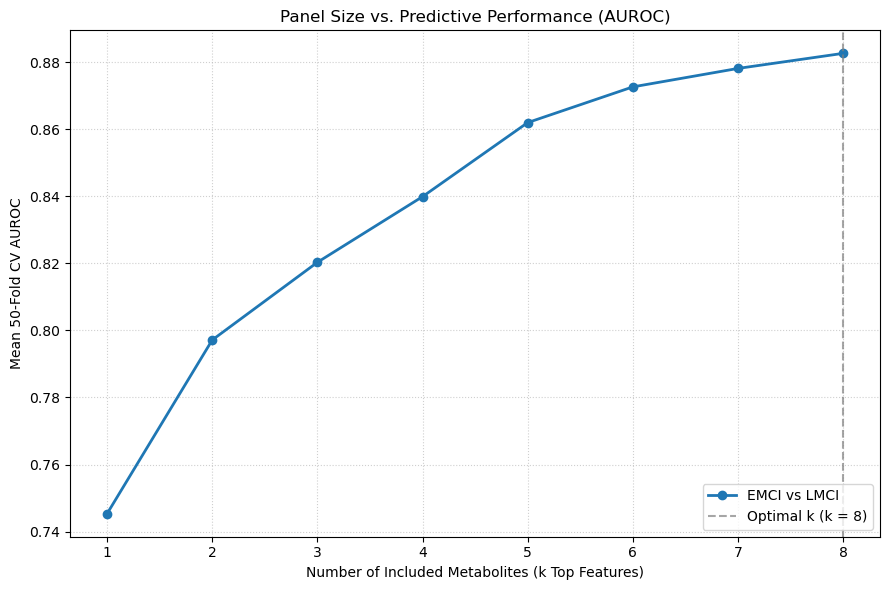

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import QuantileTransformer
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, SelectKBest, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import QuantileTransformer
from sklearn.svm import SVC
from tqdm import tqdm



ranked_metabolites = top_panels_dict["EMCI_vs_LMCI"]["Metabolite"].tolist()
max_k = len(ranked_metabolites) 

ablation_results = []

g_a = "EMCI"
g_b = "LMCI"
sub_data = df[df["BASELINE_DX"].isin(["EMCI","LMCI"])].copy()
y_sub = (sub_data["BASELINE_DX"] == g_b).astype(int).to_numpy()

rskf = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=10, random_state=42
)

for k in range(1, max_k + 1):
    # Select top k metabolites from the ranked panel
    current_features = ranked_metabolites[:k]
    feature_indices = [metabolite_cols.index(m) for m in current_features]
    X_sub = sub_data[metabolite_cols].to_numpy()[:, feature_indices]

    fold_aurocs = []
    for train_idx, val_idx in rskf.split(X_sub, y_sub):
        X_tr, X_va = X_sub[train_idx], X_sub[val_idx]
        y_tr, y_va = y_sub[train_idx], y_sub[val_idx]

    
        scaler = QuantileTransformer(
            output_distribution="normal", random_state=42
        )
        X_tr_sc = scaler.fit_transform(X_tr)
        X_va_sc = scaler.transform(X_va)

        rf = SVC(kernel="rbf", C=1.0, probability=True, class_weight="balanced", random_state=42)
        rf.fit(X_tr_sc, y_tr)

        y_prob = rf.predict_proba(X_va_sc)[:, 1]
        fold_aurocs.append(roc_auc_score(y_va, y_prob))

    ablation_results.append({
        "Comparison": f"{g_a} vs {g_b}",
        "Panel_Size": k,
        "Mean_AUROC": np.mean(fold_aurocs),
        "SD_AUROC": np.std(fold_aurocs),
    })

df_ablation = pd.DataFrame(ablation_results)


plt.figure(figsize=(9, 6))

for comparison in df_ablation["Comparison"].unique():
    sub_df = df_ablation[df_ablation["Comparison"] == comparison]
    plt.plot(
        sub_df["Panel_Size"],
        sub_df["Mean_AUROC"],
        marker="o",
        linewidth=2,
        label=comparison,
    )

plt.axvline(
    x=8, color="gray", linestyle="--", alpha=0.7, label="Optimal k (k = 8)"
)
plt.title("Panel Size vs. Predictive Performance (AUROC)")
plt.xlabel("Number of Included Metabolites (k Top Features)")
plt.ylabel("Mean 50-Fold CV AUROC")
plt.xticks(range(1, max_k + 1))
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("metabolite_panel_ablation_curve.png", dpi=300)
plt.show()

In [35]:
import pandas as pd
import numpy as np
import warnings
from scipy.stats import iqr
from tqdm import tqdm

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import QuantileTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

warnings.filterwarnings("ignore")


df = pd.read_csv("bl_progression_data (3).csv")
exclude_cols = ['RID','VISCODE','BASELINE_DX','FINAL_DX','PROGRESSION_MONTH',
                'PROGRESSED','TOTAL_VISITS','DX','DX_bl','COLPROT','ORIGPROT']
metabolite_cols = [c for c in df.columns if c not in exclude_cols]

# Extract top 8 consensus metabolites
emci_lmci_panel = top_panels_dict["EMCI_vs_LMCI"]["Metabolite"].tolist()[0:8]
panel_indices = [metabolite_cols.index(m) for m in emci_lmci_panel]

continuum_pairs = [
    ("CN", "Dementia"),
    ("CN", "EMCI"),
    ("EMCI", "LMCI"),
    ("LMCI", "Dementia")
]

chuah_1000_results = []


n_splits = 1000
sss = StratifiedShuffleSplit(n_splits=n_splits, test_size=0.20, random_state=42)


for g_a, g_b in continuum_pairs:
    sub_data = df[df["BASELINE_DX"].isin([g_a, g_b])].copy()
    X_sub = sub_data[metabolite_cols].to_numpy()[:, panel_indices] # Fixed 8-metabolite panel
    y_sub = (sub_data["BASELINE_DX"] == g_b).astype(int).to_numpy()

    split_aurocs, split_accs, split_f1s = [], [], []

    print(f"Running 1,000 Monte Carlo Splits for {g_a} vs {g_b}...")
    for train_idx, test_idx in tqdm(sss.split(X_sub, y_sub), total=n_splits):
        X_tr, X_te = X_sub[train_idx], X_sub[test_idx]
        y_tr, y_te = y_sub[train_idx], y_sub[test_idx]

        # In-fold scaling 
        scaler = QuantileTransformer(output_distribution="normal", random_state=42)
        X_tr_sc = scaler.fit_transform(X_tr)
        X_te_sc = scaler.transform(X_te)

        # Train Random Forest on fixed panel
        rf = RandomForestClassifier(
            n_estimators=300, max_depth=8, min_samples_split=5,
            min_samples_leaf=2, max_features="sqrt", class_weight="balanced", random_state=42
        )
        rf.fit(X_tr_sc, y_tr)

        y_pred = rf.predict(X_te_sc)
        y_prob = rf.predict_proba(X_te_sc)[:, 1]

        split_aurocs.append(roc_auc_score(y_te, y_prob))
        split_accs.append(accuracy_score(y_te, y_pred))
        split_f1s.append(f1_score(y_te, y_pred, average="macro"))

    # Record metrics across all partitions
    chuah_1000_results.append({
        "Comparison": f"{g_a} vs {g_b}",
        "Mean AUROC": round(np.mean(split_aurocs), 3),
        "AUROC SD (Partition Var)": round(np.std(split_aurocs), 3),
        "AUROC 95% CI": f"[{np.percentile(split_aurocs, 2.5):.3f}, {np.percentile(split_aurocs, 97.5):.3f}]",
        "AUROC IQR": round(iqr(split_aurocs), 3),
        "AUROC Range (Min - Max)": f"{np.min(split_aurocs):.3f} - {np.max(split_aurocs):.3f}",
        "Mean Accuracy ± SD": f"{np.mean(split_accs):.3f} ± {np.std(split_accs):.3f}",
        "Mean Macro F1 ± SD": f"{np.mean(split_f1s):.3f} ± {np.std(split_f1s):.3f}"
    })


df_chuah_1000 = pd.DataFrame(chuah_1000_results)
print("\n=== 1,000 Monte Carlo Partition Analysis ===")
print(df_chuah_1000.to_string(index=False))

df_chuah_1000.to_csv("chuah_1000_monte_carlo_results.csv", index=False)

Running 1,000 Monte Carlo Splits for CN vs Dementia...


100%|███████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [18:58<00:00,  1.14s/it]


Running 1,000 Monte Carlo Splits for CN vs EMCI...


100%|█████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [1:07:46<00:00,  4.07s/it]


Running 1,000 Monte Carlo Splits for EMCI vs LMCI...


100%|███████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [21:35<00:00,  1.30s/it]


Running 1,000 Monte Carlo Splits for LMCI vs Dementia...


100%|███████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [21:02<00:00,  1.26s/it]


=== True Chuah et al. (2022) 1,000 Monte Carlo Partition Analysis ===
      Comparison  Mean AUROC  AUROC SD (Partition Var)   AUROC 95% CI  AUROC IQR AUROC Range (Min - Max) Mean Accuracy ± SD Mean Macro F1 ± SD
  CN vs Dementia       0.632                     0.045 [0.543, 0.720]      0.062           0.483 - 0.807      0.613 ± 0.041      0.587 ± 0.042
      CN vs EMCI       0.798                     0.037 [0.724, 0.867]      0.050           0.667 - 0.907      0.703 ± 0.040      0.693 ± 0.041
    EMCI vs LMCI       0.893                     0.024 [0.844, 0.939]      0.032           0.811 - 0.964      0.812 ± 0.030      0.801 ± 0.031
LMCI vs Dementia       0.547                     0.047 [0.458, 0.639]      0.063           0.374 - 0.733      0.576 ± 0.040      0.518 ± 0.041


In [36]:
import pandas as pd
import numpy as np
import warnings
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import QuantileTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

warnings.filterwarnings('ignore')


df_prog = pd.read_csv("bl_progression_data (3).csv")
adni_df = pd.read_csv("ADNIMERGE_ (3).csv", low_memory=False)

# Map baseline study phase labels (ORIGPROT) by RID
adni_bl = adni_df[adni_df['VISCODE'] == 'bl'][['RID', 'ORIGPROT']].drop_duplicates('RID')
df_merged = pd.merge(df_prog, adni_bl, on='RID', how='left')

# Standardize disease labels
df_merged['BASELINE_DX'] = df_merged['BASELINE_DX'].replace({'AD': 'Dementia'})

# Define top 8-metabolite consensus panel
metabolite_cols = df_prog.columns[8:].tolist()
emci_lmci_panel = [
    'GLYCERIC_ACID', 'C8_0', 'X3_DHCA', 'GHDCA', 
    'HCA', 'TAMCA', 'C19_2_CIS_10_13', 'X__2_METHYLPENTANOIC_ACID'
]
panel_indices = [metabolite_cols.index(m) for m in emci_lmci_panel]

continuum_pairs = [
    ("CN", "Dementia"),
    ("CN", "EMCI"),
    ("EMCI", "LMCI"),
    ("LMCI", "Dementia")
]


phase_accuracy_results = []

for g_a, g_b in continuum_pairs:
    sub_data = df_merged[df_merged["BASELINE_DX"].isin([g_a, g_b])].copy().reset_index(drop=True)
    X_sub = sub_data[metabolite_cols].to_numpy()[:, panel_indices]
    y_sub = (sub_data["BASELINE_DX"] == g_b).astype(int).to_numpy() # 0 = g_a, 1 = g_b
    phases = sub_data["ORIGPROT"].to_numpy()
    
    # 5x10 RSKF CV
    rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
    oof_probs_matrix = np.zeros((len(sub_data), 10))
    
    for fold_idx, (train_idx, val_idx) in tqdm(enumerate(rskf.split(X_sub, y_sub))):
        rep = fold_idx // 5
        X_tr, X_va = X_sub[train_idx], X_sub[val_idx]
        y_tr, y_va = y_sub[train_idx], y_sub[val_idx]
        
        scaler = QuantileTransformer(output_distribution="normal", random_state=42)
        X_tr_sc = scaler.fit_transform(X_tr)
        X_va_sc = scaler.transform(X_va)
        
        rf = RandomForestClassifier(
            n_estimators=300, max_depth=8, min_samples_split=5,
            min_samples_leaf=2, max_features="sqrt", class_weight="balanced", random_state=42
        )
        rf.fit(X_tr_sc, y_tr)
        
        if len(rf.classes_) == 2:
            y_prob = rf.predict_proba(X_va_sc)[:, 1]
        else:
            y_prob = np.full(len(X_va), rf.classes_[0])
            
        oof_probs_matrix[val_idx, rep] = y_prob

    # Ensemble out-of-fold predictions
    oof_probs = oof_probs_matrix.mean(axis=1)
    oof_preds = (oof_probs >= 0.5).astype(int)
    
    # Stratify by ADNI Study Phase
    for phase_name in ['ADNI1', 'ADNIGO', 'ADNI2']:
        mask_phase = (phases == phase_name)
        if mask_phase.sum() == 0:
            continue
        
        y_p = y_sub[mask_phase]
        preds_p = oof_preds[mask_phase]
        n_total = len(y_p)
        
        # Overall accuracy in phase
        phase_acc = accuracy_score(y_p, preds_p)
        
        # Group A Share Correct (Class 0)
        mask_a = (y_p == 0)
        n_a = mask_a.sum()
        correct_a = (preds_p[mask_a] == 0).sum() if n_a > 0 else 0
        share_a_str = f"{correct_a / n_a:.1%} ({correct_a}/{n_a})" if n_a > 0 else "N/A (n=0)"
        
        # Group B Share Correct (Class 1)
        mask_b = (y_p == 1)
        n_b = mask_b.sum()
        correct_b = (preds_p[mask_b] == 1).sum() if n_b > 0 else 0
        share_b_str = f"{correct_b / n_b:.1%} ({correct_b}/{n_b})" if n_b > 0 else "N/A (n=0)"
        
        phase_accuracy_results.append({
            "Comparison": f"{g_a} vs {g_b}",
            "Study Phase": phase_name,
            "Total N": n_total,
            "Overall Phase Accuracy": f"{phase_acc:.1%} ({sum(preds_p == y_p)}/{n_total})",
            f"{g_a} Share Correct": share_a_str,
            f"{g_b} Share Correct": share_b_str
        })

# Display formatted dataframe
df_phase_acc = pd.DataFrame(phase_accuracy_results)
print("=== Stratified Phase Accuracy & Group Recall Summary ===")
print(df_phase_acc.to_string(index=False))

50it [00:55,  1.11s/it]
50it [00:55,  1.11s/it]
50it [00:57,  1.14s/it]
50it [00:57,  1.16s/it]

=== Stratified Phase Accuracy & Group Recall Summary ===
      Comparison Study Phase  Total N Overall Phase Accuracy CN Share Correct Dementia Share Correct EMCI Share Correct LMCI Share Correct
  CN vs Dementia       ADNI1      338        57.7% (195/338)   51.3% (99/193)         66.2% (96/145)                NaN                NaN
  CN vs Dementia       ADNI2      198        69.7% (138/198)  82.8% (130/157)           19.5% (8/41)                NaN                NaN
      CN vs EMCI       ADNI1      193        94.3% (182/193)  94.3% (182/193)                    NaN          N/A (n=0)                NaN
      CN vs EMCI      ADNIGO      108        92.6% (100/108)        N/A (n=0)                    NaN    92.6% (100/108)                NaN
      CN vs EMCI       ADNI2      271        44.6% (121/271)   45.2% (71/157)                    NaN     43.9% (50/114)                NaN
    EMCI vs LMCI       ADNI1      320        95.3% (305/320)              NaN                    NaN         

Observed Mean AUROC (True Labels): 0.8825

Running Permutation Testing...


100%|█████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [42:35<00:00, 12.78s/it]



Permutation Test p-value: 4.9751e-03


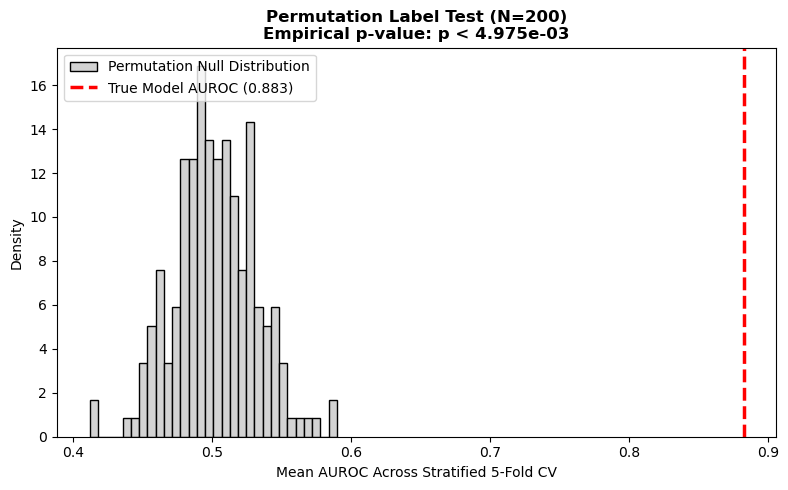

In [52]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import QuantileTransformer
from tqdm import tqdm


df = pd.read_csv("bl_progression_data (3).csv")
sub_data = df[df["BASELINE_DX"].isin(["EMCI", "LMCI"])].copy()

exclude_cols = [
    "RID",
    "VISCODE",
    "BASELINE_DX",
    "FINAL_DX",
    "PROGRESSION_MONTH",
    "PROGRESSED",
    "TOTAL_VISITS",
    "DX",
    "DX_bl",
    "COLPROT",
    "ORIGPROT",
]
metabolite_cols = [c for c in sub_data.columns if c not in exclude_cols]

X = sub_data[metabolite_cols].to_numpy()
y = (sub_data["BASELINE_DX"] == "LMCI").astype(int).to_numpy()



def evaluate_pipeline(X_data, y_data, seed=42):
  cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
  auroc_scores = []

  for train_idx, val_idx in cv.split(X_data, y_data):
    X_tr, X_va = X_data[train_idx], X_data[val_idx]
    y_tr, y_va = y_data[train_idx], y_data[val_idx]

    # Preprocessing
    scaler = QuantileTransformer(output_distribution="normal", random_state=seed)
    X_tr_sc = scaler.fit_transform(X_tr)
    X_va_sc = scaler.transform(X_va)

    # Filter Selection (MI Top 30)
    selector = SelectKBest(
        score_func=lambda x_in, y_in: mutual_info_classif(
            x_in, y_in, random_state=seed
        ),
        k=30,
    )
    X_tr_k = selector.fit_transform(X_tr_sc, y_tr)
    X_va_k = selector.transform(X_va_sc)

    # Wrapper Selection (RFE Top 8)
    log_reg = LogisticRegression(
        penalty="l1", solver="liblinear", random_state=seed
    )
    rfe = RFE(log_reg, n_features_to_select=8)
    X_tr_rfe = rfe.fit_transform(X_tr_k, y_tr)
    X_va_rfe = rfe.transform(X_va_k)

    # Classifier Training & Scoring
    rf = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        random_state=seed,
    )
    rf.fit(X_tr_rfe, y_tr)
    y_prob = rf.predict_proba(X_va_rfe)[:, 1]

    auroc_scores.append(roc_auc_score(y_va, y_prob))

  return np.mean(auroc_scores)



true_auroc = evaluate_pipeline(X, y, seed=42)
print(f"Observed Mean AUROC (True Labels): {true_auroc:.4f}")


n_permutations = 200
permuted_aurocs = []
np.random.seed(42)

print("\nRunning Permutation Testing...")
for i in tqdm(range(n_permutations)):
  y_permuted = np.random.permutation(y)
  perm_score = evaluate_pipeline(X, y_permuted, seed=i)
  permuted_aurocs.append(perm_score)

permuted_aurocs = np.array(permuted_aurocs)


p_value = (np.sum(permuted_aurocs >= true_auroc) + 1) / (n_permutations + 1)
print(f"\nPermutation Test p-value: {p_value:.4e}")


plt.figure(figsize=(8, 5))
plt.hist(
    permuted_aurocs,
    bins=30,
    color="lightgray",
    edgecolor="black",
    density=True,
    label="Permutation Null Distribution",
)
plt.axvline(
    true_auroc,
    color="red",
    linestyle="--",
    linewidth=2.5,
    label=f"True Model AUROC ({true_auroc:.3f})",
)
plt.title(
    f"Permutation Label Test (N={n_permutations})\nEmpirical p-value: p <"
    f" {p_value:.3e}",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Mean AUROC Across Stratified 5-Fold CV")
plt.ylabel("Density")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("permutation_null_distribution.png", dpi=300)
plt.show()

In [33]:

# Evaluate Fixed EMCI vs LMCI Panel Across Other Pairs

df = pd.read_csv("bl_progression_data (3).csv")
sub_data = df[df["BASELINE_DX"].isin(["EMCI", "LMCI"])].copy()
# 1. Extract the top 15 metabolites from the EMCI vs LMCI consensus panel
emci_lmci_panel = top_panels_dict["EMCI_vs_LMCI"]["Metabolite"].tolist()[0:8]
panel_indices = [metabolite_cols.index(m) for m in emci_lmci_panel]

transfer_results = []


for g_a, g_b in continuum_pairs:
    print(g_a, " ", g_b)


    # Filter data for current pair
    sub_data = df[df["BASELINE_DX"].isin([g_a, g_b])].copy()
    X_sub = sub_data[metabolite_cols].to_numpy()[:, panel_indices]  # Restrict to fixed panel
    y_sub = (sub_data["BASELINE_DX"] == g_b).astype(int).to_numpy()

    rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
    accs, f1s, aurocs = [], [], []

    # Cross-validation loop over the fixed feature set
    for train_idx, val_idx in tqdm(rskf.split(X_sub, y_sub)):
        X_tr, X_va = X_sub[train_idx], X_sub[val_idx]
        y_tr, y_va = y_sub[train_idx], y_sub[val_idx]

        # Scaler fit inside fold
        scaler = QuantileTransformer(output_distribution="normal", random_state=42)
        X_tr_sc = scaler.fit_transform(X_tr)
        X_va_sc = scaler.transform(X_va)

        # Train Random Forest on the fixed 15-metabolite panel
        rf = RandomForestClassifier(
            n_estimators=300, max_depth=8, min_samples_split=5,
            min_samples_leaf=2, max_features="sqrt", class_weight="balanced", random_state=42
        )
        rf.fit(X_tr_sc, y_tr)

        y_pred = rf.predict(X_va_sc)
        y_prob = rf.predict_proba(X_va_sc)[:, 1]

        accs.append(accuracy_score(y_va, y_pred))
        f1s.append(f1_score(y_va, y_pred, average="macro"))
        aurocs.append(roc_auc_score(y_va, y_prob))

    transfer_results.append({
        "Comparison": f"{g_a} vs {g_b}",
        "AUROC (Mean ± SD)": f"{np.mean(aurocs):.3f} ± {np.std(aurocs):.3f}",
        "Accuracy (Mean ± SD)": f"{np.mean(accs):.3f} ± {np.std(accs):.3f}",
        "Macro F1 (Mean ± SD)": f"{np.mean(f1s):.3f} ± {np.std(f1s):.3f}"
    })

# Output Summary Table
df_transfer = pd.DataFrame(transfer_results)
print("=== Performance of Fixed EMCI/LMCI Panel Across Other Transitions ===")
print(df_transfer.to_string(index=False))

CN   Dementia


50it [01:03,  1.27s/it]


CN   EMCI


50it [01:03,  1.28s/it]


EMCI   LMCI


50it [01:05,  1.31s/it]


LMCI   Dementia


50it [01:08,  1.38s/it]

=== Performance of Fixed EMCI/LMCI Panel Across Other Transitions ===
      Comparison AUROC (Mean ± SD) Accuracy (Mean ± SD) Macro F1 (Mean ± SD)
  CN vs Dementia     0.637 ± 0.044        0.620 ± 0.039        0.595 ± 0.040
      CN vs EMCI     0.799 ± 0.035        0.699 ± 0.048        0.688 ± 0.049
    EMCI vs LMCI     0.895 ± 0.018        0.812 ± 0.024        0.801 ± 0.024
LMCI vs Dementia     0.552 ± 0.045        0.581 ± 0.039        0.527 ± 0.039


In [50]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# Load Data & Calculate CSF Ratio
gut_df = pd.read_csv('ADMCGUTMETABOLITES.csv')
adni_df = pd.read_csv('ADNIMERGE_ (3).csv', low_memory=False)

gut_bl = gut_df[gut_df['VISCODE'].isin(['bl', 'm00', 'm0'])].copy()
adni_bl = adni_df[adni_df['VISCODE'] == 'bl'].copy()
df = pd.merge(gut_bl, adni_bl, on='RID')

# Clean numeric CSF variables
df['PTAU_num'] = pd.to_numeric(
    df['PTAU_bl'].astype(str).str.replace('>', '').str.replace('<', ''),
    errors='coerce',
)
df['ABETA_num'] = pd.to_numeric(
    df['ABETA_bl'].astype(str).str.replace('>', '').str.replace('<', ''),
    errors='coerce',
)
df['CSF_PTAU_ABETA_RATIO'] = df['PTAU_num'] / df['ABETA_num']

# Panel Metabolites Copy+Paste
panel_metabolites = [
    'GLYCERIC_ACID',
    'C8_0',
    'X3_DHCA',
    'GHDCA',
    'HCA',
    'TAMCA',
    'C19_2_CIS_10_13',
    'X__2_METHYLPENTANOIC_ACID',
    'C10_0',
    'X2_HYDROXYBUTYRIC_ACID',
    'C6_0',
    'ALLOLCA',
    'C4_0',
    'SUCCINIC_ACID',
    'C12_0',
]

# Compute Spearman correlations
corr_results = []
valid_df = df.dropna(subset=['CSF_PTAU_ABETA_RATIO', 'ADAS13', 'LDELTOTAL']).copy()

for meta in panel_metabolites:
    if meta in valid_df.columns:
        valid_meta_df = valid_df.dropna(subset=[meta])
        rho_csf, p_val_csf = spearmanr(
            valid_meta_df[meta], valid_meta_df['CSF_PTAU_ABETA_RATIO']
        )
        rho_ldel, p_val_ldel = spearmanr(
            valid_meta_df[meta], valid_meta_df['LDELTOTAL']
        )
        rho_adas, p_val_adas = spearmanr(
            valid_meta_df[meta], valid_meta_df['ADAS13']
        )
        

        
        corr_results.append({
            'Metabolite': meta,
            'Spearman CSF': rho_csf,
            'P-Value CSF': p_val_csf,
            'Spearman LDELTOTAL': rho_ldel,
            'P-Value LDELTOTAL': p_val_ldel,
            'Spearman ADAS13': rho_adas,
            'P-Value ADAS13': p_val_adas,
        })

df_corr = pd.DataFrame(corr_results)

# Benjamini-Hochberg FDR Correction
_, q_vals_csf, _, _ = multipletests(df_corr['P-Value CSF'], method='fdr_bh')
df_corr['Q-Value CSF'] = q_vals_csf

_, q_vals_ldel, _, _ = multipletests(df_corr['P-Value LDELTOTAL'], method='fdr_bh')
df_corr['Q-Value LDELTOTAL'] = q_vals_ldel

_, q_vals_adas, _, _ = multipletests(df_corr['P-Value ADAS13'], method='fdr_bh')
df_corr['Q-Value ADAS13'] = q_vals_adas

# Format Table
df_corr['Spearman CSF'] = df_corr['Spearman CSF'].round(3)
df_corr['P-Value CSF'] = df_corr['P-Value CSF'].apply(lambda x: f'{x:.4e}')
df_corr['Q-Value CSF'] = df_corr['Q-Value CSF'].apply(lambda x: f'{x:.4e}')

df_corr['Spearman LDELTOTAL'] = df_corr['Spearman LDELTOTAL'].round(3)
df_corr['P-Value LDELTOTAL'] = df_corr['P-Value LDELTOTAL'].apply(lambda x: f'{x:.4e}')
df_corr['Q-Value LDELTOTAL'] = df_corr['Q-Value LDELTOTAL'].apply(lambda x: f'{x:.4e}')

df_corr['Spearman ADAS13'] = df_corr['Spearman ADAS13'].round(3)
df_corr['P-Value ADAS13'] = df_corr['P-Value ADAS13'].apply(lambda x: f'{x:.4e}')
df_corr['Q-Value ADAS13'] = df_corr['Q-Value ADAS13'].apply(lambda x: f'{x:.4e}')

df_corr.to_csv(
    'Table_S3_CSF_PTau_Abeta_Ratio_Correlations.csv', index=False
)
print(
    'Supplemental Table S3'
)
df_corr.head()

Supplemental Table S3


,Metabolite,Spearman CSF,P-Value CSF,Spearman LDELTOTAL,P-Value LDELTOTAL,Spearman ADAS13,P-Value ADAS13,Q-Value CSF,Q-Value LDELTOTAL,Q-Value ADAS13
0,GLYCERIC_ACID,0.119,1.3070e-02,-0.145,2.4074e-03,0.172,3.3167e-04,9.8026e-02,1.2037e-02,2.4875e-03
1,C8_0,-0.066,1.7308e-01,0.161,7.5104e-04,-0.096,4.4832e-02,4.3270e-01,5.6328e-03,1.6812e-01
2,X3_DHCA,-0.033,4.9248e-01,0.048,3.1956e-01,-0.078,1.0603e-01,6.8957e-01,4.3577e-01,1.9880e-01
3,GHDCA,0.185,1.0786e-04,-0.200,2.7543e-05,0.219,4.1453e-06,1.6179e-03,4.1315e-04,6.2179e-05
4,HCA,0.020,6.8223e-01,-0.101,3.4749e-02,0.054,2.6492e-01,7.7890e-01,1.0425e-01,3.9738e-01


In [3]:
# Imports and configuration
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

# Load raw ADNI data files
admc_metab = pd.read_csv('ADMCGUTMETABOLITES.csv')
admc_dict = pd.read_csv('ADMCGUTMETABOLITESLONG_DICT (1) (2) (1).csv')
adnimerge = pd.read_csv('ADNIMERGE_ (3).csv', low_memory=False)

# Identify the 104 target metabolite columns (excluding system metadata)
non_metab_cols = [
    'RID',
    'VISCODE',
    'VISCODE2',
    'EXAMDATE',
    'DRAWDATE',
    'SAMPLE_ID',
    'VID',
    'DRAWTIME',
    'update_stamp',
]
metab_104 = [c for c in admc_metab.columns if c not in non_metab_cols]
assert (
    len(metab_104) == 104
), f"Expected 104 metabolites, found {len(metab_104)}"

# Filter baseline visit records (VISCODE2 == 'bl')
bl_admc = admc_metab[admc_metab['VISCODE2'] == 'bl'].copy()
bl_adnimerge = adnimerge[adnimerge['VISCODE'] == 'bl'].copy()

# Merge baseline metabolomics with clinical annotations from ADNIMERGE
merged_bl = pd.merge(
    bl_admc,
    bl_adnimerge,
    on='RID',
    how='inner',
    suffixes=('', '_adnimerge'),
)
merged_bl = merged_bl.dropna(subset=['DX_bl'])

print(
    f"Baseline cohort merged successfully: N = {len(merged_bl)} total participants across 104 analytes."
)


def generate_table_1(df):
    groups = ['CN', 'EMCI', 'LMCI', 'AD']
    rows = []

    # Total Count
    row_n = {'Characteristic': 'Participants, N'}
    for g in groups:
        row_n[g] = str(len(df[df['DX_bl'] == g]))
    rows.append(row_n)

    # Phase Breakdown
    for p in ['ADNI1', 'ADNIGO', 'ADNI2']:
        row_p = {'Characteristic': f'Enrollment Phase: {p}, n (%)'}
        for g in groups:
            sub = df[df['DX_bl'] == g]
            cnt = len(sub[sub['ORIGPROT'] == p])
            pct = (cnt / len(sub) * 100) if len(sub) > 0 else 0
            row_p[g] = f'{cnt} ({pct:.1f}%)'
        rows.append(row_p)

    # Age (Years)
    row_age = {'Characteristic': 'Age, years (Mean ± SD)'}
    for g in groups:
        vals = df[df['DX_bl'] == g]['AGE'].dropna()
        row_age[g] = f'{vals.mean():.1f} ± {vals.std():.1f}'
    rows.append(row_age)

    # Sex (% Female)
    row_sex = {'Characteristic': 'Sex, % Female (n)'}
    for g in groups:
        sub = df[df['DX_bl'] == g]
        fem = len(sub[sub['PTGENDER'] == 'Female'])
        pct = (fem / len(sub) * 100) if len(sub) > 0 else 0
        row_sex[g] = f'{pct:.1f}% ({fem})'
    rows.append(row_sex)

    # Education (Years)
    row_edu = {'Characteristic': 'Education, years (Mean ± SD)'}
    for g in groups:
        vals = df[df['DX_bl'] == g]['PTEDUCAT'].dropna()
        row_edu[g] = f'{vals.mean():.1f} ± {vals.std():.1f}'
    rows.append(row_edu)

    # APOE4 Positive Carrier Status
    row_apoe = {'Characteristic': 'APOE ε4 Carriers, % (n)'}
    for g in groups:
        sub = df[df['DX_bl'] == g]['APOE4'].dropna()
        pos = (sub > 0).sum()
        pct = (pos / len(sub) * 100) if len(sub) > 0 else 0
        row_apoe[g] = f'{pct:.1f}% ({pos})'
    rows.append(row_apoe)

    # ADAS-Cog13
    row_adas = {'Characteristic': 'ADAS-Cog13 Score (Mean ± SD)'}
    for g in groups:
        vals = df[df['DX_bl'] == g]['ADAS13'].dropna()
        row_adas[g] = f'{vals.mean():.1f} ± {vals.std():.1f}'
    rows.append(row_adas)

    # Logical Memory Delayed Recall (LDELTOTAL)
    row_ldel = {'Characteristic': 'Logical Memory Delayed (LDELTOTAL)'}
    for g in groups:
        vals = df[df['DX_bl'] == g]['LDELTOTAL'].dropna()
        row_ldel[g] = f'{vals.mean():.1f} ± {vals.std():.1f}'
    rows.append(row_ldel)

    return pd.DataFrame(rows)


# Execute and display Table 1
table_1_df = generate_table_1(merged_bl)
table_1_df.to_csv('Table_1_Baseline_Characteristics.csv', index=False)
display(table_1_df)

Baseline cohort merged successfully: N = 1180 total participants across 104 analytes.


,Characteristic,CN,EMCI,LMCI,AD
0,"Participants, N",350,222,422,186
1,"Enrollment Phase: ADNI1, n (%)",193 (55.1%),0 (0.0%),321 (76.1%),145 (78.0%)
2,"Enrollment Phase: ADNIGO, n (%)",0 (0.0%),108 (48.6%),0 (0.0%),0 (0.0%)
3,"Enrollment Phase: ADNI2, n (%)",157 (44.9%),114 (51.4%),101 (23.9%),41 (22.0%)
4,"Age, years (Mean ± SD)",74.8 ± 5.7,71.0 ± 7.4,74.1 ± 7.3,75.2 ± 7.8
5,"Sex, % Female (n)",48.3% (169),47.7% (106),39.6% (167),44.6% (83)
6,"Education, years (Mean ± SD)",16.4 ± 2.7,16.1 ± 2.7,16.0 ± 2.8,14.9 ± 3.0
7,"APOE ε4 Carriers, % (n)",28.3% (99),41.9% (93),54.7% (231),68.3% (127)
8,ADAS-Cog13 Score (Mean ± SD),9.1 ± 4.2,12.4 ± 5.2,18.7 ± 6.5,29.1 ± 7.7
9,Logical Memory Delayed (LDELTOTAL),13.4 ± 3.3,8.9 ± 1.7,3.9 ± 2.6,1.4 ± 2.0


In [5]:
def bootstrap_median_diff_ci(
    g_emci, g_lmci, n_bootstraps=2000, ci=95, seed=42
):
    np.random.seed(seed)
    diffs = []
    g1, g2 = np.asarray(g_emci), np.asarray(g_lmci)
    for _ in range(n_bootstraps):
        b1 = np.random.choice(g1, size=len(g1), replace=True)
        b2 = np.random.choice(g2, size=len(g2), replace=True)
        diffs.append(np.median(b2) - np.median(b1))
    alpha = (100 - ci) / 2.0
    return np.percentile(diffs, alpha), np.percentile(diffs, 100 - alpha)


# Filter primary cohort comparison (EMCI vs. LMCI)
primary_df = merged_bl[merged_bl['DX_bl'].isin(['EMCI', 'LMCI'])].copy()

primary_df = primary_df.dropna(subset=metab_104, how='any')

print(f"Final analyzed cohort count: N = {len(primary_df)}")  

# Build dictionary mapping for HMDB IDs and Metabolite Names
dict_lookup = {}
for _, row in admc_dict.iterrows():
    fld = row['FLDNAME']
    if fld in metab_104:
        hmdb = str(row['NOTES']) if pd.notnull(row['NOTES']) else 'N/A'
        txt = str(row['TEXT']) if pd.notnull(row['TEXT']) else fld
        dict_lookup[fld] = {'HMDB_ID': hmdb, 'TEXT': txt}

results_s2 = []

for met in metab_104:
    emci_vals = (
        primary_df[primary_df['DX_bl'] == 'EMCI'][met].dropna().values
    )
    lmci_vals = (
        primary_df[primary_df['DX_bl'] == 'LMCI'][met].dropna().values
    )

    # Medians and IQRs
    e_q25, e_med, e_q75 = np.percentile(emci_vals, [25, 50, 75])
    l_q25, l_med, l_q75 = np.percentile(lmci_vals, [25, 50, 75])
    med_iqr_emci = f'{e_med:.4f} [{e_q25:.4f}–{e_q75:.4f}]'
    med_iqr_lmci = f'{l_med:.4f} [{l_q25:.4f}–{l_q75:.4f}]'

    # Unadjusted Mann-Whitney U Test
    u_stat, unadj_p = stats.mannwhitneyu(
        lmci_vals, emci_vals, alternative='two-sided'
    )

    # Median Difference & Bootstrap 95% CI
    med_diff = l_med - e_med
    ci_low, ci_high = bootstrap_median_diff_ci(emci_vals, lmci_vals)

    # Log2 Ratio of Means (LMCI vs EMCI)
    mean_e, mean_l = np.mean(emci_vals), np.mean(lmci_vals)
    log2_ratio = (
        np.log2(mean_l / mean_e) if (mean_e > 0 and mean_l > 0) else np.nan
    )

    # Covariate-Adjusted OLS Regression (Standardized Analyte ~ DX + Covariates)
    cov_cols = ['DX_bl', 'AGE', 'PTGENDER', 'PTEDUCAT', 'APOE4', 'ORIGPROT', met]
    reg_df = primary_df[cov_cols].dropna().copy()

    reg_df['DX_NUM'] = (reg_df['DX_bl'] == 'LMCI').astype(float)
    reg_df['MET_STD'] = (reg_df[met] - reg_df[met].mean()) / reg_df[met].std()

    X_design = pd.get_dummies(
        reg_df[['DX_NUM', 'AGE', 'PTGENDER', 'PTEDUCAT', 'APOE4', 'ORIGPROT']],
        columns=['PTGENDER', 'ORIGPROT'],
        drop_first=True,
        dtype=float,
    )
    X_design = sm.add_constant(X_design)
    y_design = reg_df['MET_STD']

    try:
        ols_fit = sm.OLS(y_design, X_design).fit()
        adj_n = int(ols_fit.nobs)
        adj_beta = ols_fit.params['DX_NUM']
        adj_beta_ci_low, adj_beta_ci_high = ols_fit.conf_int().loc['DX_NUM']
        adj_p = ols_fit.pvalues['DX_NUM']
        adj_r2 = ols_fit.rsquared
    except Exception:
        adj_n = len(reg_df)
        adj_beta = adj_beta_ci_low = adj_beta_ci_high = adj_p = adj_r2 = np.nan

    hmdb_val = dict_lookup.get(met, {}).get('HMDB_ID', 'N/A')

    # Assign broad chemical class
    if 'CA' in met or 'DCA' in met or 'HCA' in met or 'BA' in met:
        chem_class = 'Bile Acid'
    elif met.startswith('C') and ('_' in met or met[1:].isdigit()):
        chem_class = 'Free Fatty Acid'
    elif 'ACID' in met:
        chem_class = 'Organic Acid'
    else:
        chem_class = 'Amino Acid / Derivative'

    results_s2.append({
        'Metabolite_Name': met,
        'HMDB_ID': hmdb_val,
        'Chemical_Class': chem_class,
        'Median_IQR_EMCI': med_iqr_emci,
        'Median_IQR_LMCI': med_iqr_lmci,
        'Mann_Whitney_U': u_stat,
        'Unadjusted_p': unadj_p,
        'Median_Difference_LMCI_minus_EMCI': med_diff,
        'Median_Difference_95CI_Lower': ci_low,
        'Median_Difference_95CI_Upper': ci_high,
        'Log2_Ratio_of_Means_LMCI_vs_EMCI': log2_ratio,
        'Adjusted_N': adj_n,
        'Adjusted_Beta_LMCI_minus_EMCI': adj_beta,
        'Adjusted_Beta_95CI_Lower': adj_beta_ci_low,
        'Adjusted_Beta_95CI_Upper': adj_beta_ci_high,
        'Adjusted_p': adj_p,
        'Adjusted_Model_R2': adj_r2,
        'Adjusted_Model_Covariates': (
            'AGE + PTGENDER + PTEDUCAT + APOE4 + ORIGPROT'
        ),
    })

table_s2_df = pd.DataFrame(results_s2)

# Apply Benjamini-Hochberg False Discovery Rate (BH-FDR) Adjustments
table_s2_df['Unadjusted_FDR_q'] = multipletests(
    table_s2_df['Unadjusted_p'], method='fdr_bh'
)[1]
table_s2_df['Adjusted_FDR_q'] = multipletests(
    table_s2_df['Adjusted_p'].fillna(1.0), method='fdr_bh'
)[1]

# Enforce exact column order specified in rebuttal guidelines
final_cols = [
    'Metabolite_Name',
    'HMDB_ID',
    'Chemical_Class',
    'Median_IQR_EMCI',
    'Median_IQR_LMCI',
    'Mann_Whitney_U',
    'Unadjusted_p',
    'Median_Difference_LMCI_minus_EMCI',
    'Median_Difference_95CI_Lower',
    'Median_Difference_95CI_Upper',
    'Log2_Ratio_of_Means_LMCI_vs_EMCI',
    'Adjusted_N',
    'Adjusted_Beta_LMCI_minus_EMCI',
    'Adjusted_Beta_95CI_Lower',
    'Adjusted_Beta_95CI_Upper',
    'Adjusted_p',
    'Adjusted_Model_R2',
    'Adjusted_Model_Covariates',
    'Unadjusted_FDR_q',
    'Adjusted_FDR_q',
]

table_s2_df = table_s2_df[final_cols]
table_s2_df.to_csv(
    'Table_S2_104_Metabolites_Univariate_Adjusted.csv', index=False
)
display(table_s2_df.head(10))

Final analyzed cohort count: N = 643


,Metabolite_Name,HMDB_ID,Chemical_Class,Median_IQR_EMCI,Median_IQR_LMCI,Mann_Whitney_U,Unadjusted_p,Median_Difference_LMCI_minus_EMCI,Median_Difference_95CI_Lower,Median_Difference_95CI_Upper,Log2_Ratio_of_Means_LMCI_vs_EMCI,Adjusted_N,Adjusted_Beta_LMCI_minus_EMCI,Adjusted_Beta_95CI_Lower,Adjusted_Beta_95CI_Upper,Adjusted_p,Adjusted_Model_R2,Adjusted_Model_Covariates,Unadjusted_FDR_q,Adjusted_FDR_q
0,L_HISTIDINE,HMDB00177,Amino Acid / Derivative,91.1395 [82.6321–99.4755],90.3461 [83.8960–99.4440],47050.0,8.869117e-01,-0.793450,-2.837342,2.534887,0.019432,643,-0.071783,-0.340734,0.197168,0.600382,0.023973,AGE + PTGENDER + PTEDUCAT + APOE4 + ORIGPROT,9.317052e-01,0.991416
1,L_LYSINE,HMDB00182,Amino Acid / Derivative,238.1835 [206.0845–271.1628],228.2460 [196.2270–268.4120],42305.5,4.817720e-02,-9.937500,-20.050050,-2.276413,-0.023279,643,0.016664,-0.252099,0.285426,0.903134,0.025339,AGE + PTGENDER + PTEDUCAT + APOE4 + ORIGPROT,1.284725e-01,0.991416
2,L_SERINE,HMDB00187,Amino Acid / Derivative,126.6480 [105.5325–154.1905],129.7980 [106.7280–156.3350],48258.5,4.953533e-01,3.150000,-2.749275,8.588275,0.039137,643,-0.016518,-0.280859,0.247824,0.902380,0.057143,AGE + PTGENDER + PTEDUCAT + APOE4 + ORIGPROT,6.778519e-01,0.991416
3,BETA_ALANINE,HMDB00056,Amino Acid / Derivative,5.1511 [4.2246–6.5226],5.3407 [4.2331–6.5256],47541.5,7.175970e-01,0.189645,-0.185070,0.519522,0.031164,643,0.030206,-0.232580,0.292993,0.821492,0.068201,AGE + PTGENDER + PTEDUCAT + APOE4 + ORIGPROT,8.480691e-01,0.991416
4,L_ALANINE,HMDB00161,Amino Acid / Derivative,465.4500 [399.2303–528.3615],463.6670 [400.1740–546.7560],47692.5,6.678540e-01,-1.783000,-16.888163,11.111000,0.021010,643,0.076588,-0.193232,0.346408,0.577454,0.017655,AGE + PTGENDER + PTEDUCAT + APOE4 + ORIGPROT,7.983542e-01,0.991416
5,L_TYROSINE,HMDB00158,Amino Acid / Derivative,71.4462 [64.5032–85.3238],73.7393 [64.4767–83.5117],47138.0,8.559705e-01,2.293050,-2.253210,5.313700,0.009536,643,-0.017713,-0.286089,0.250663,0.896921,0.028141,AGE + PTGENDER + PTEDUCAT + APOE4 + ORIGPROT,9.307194e-01,0.991416
6,L_ASPARAGINE,HMDB00168,Amino Acid / Derivative,33.1943 [28.5842–41.1241],34.7815 [28.4910–44.2641],50193.0,1.222034e-01,1.587200,-0.680491,3.094927,0.069929,643,0.104797,-0.165165,0.374759,0.446168,0.016621,AGE + PTGENDER + PTEDUCAT + APOE4 + ORIGPROT,2.491992e-01,0.991416
7,L_ASPARTIC_ACID,HMDB00191,Organic Acid,10.2877 [7.9865–12.5234],12.1423 [9.8432–14.5596],62173.0,5.395286e-12,1.854600,1.268550,2.586280,0.275111,643,0.073969,-0.178287,0.326225,0.564943,0.141383,AGE + PTGENDER + PTEDUCAT + APOE4 + ORIGPROT,1.870366e-10,0.991416
8,HIPPURIC_ACID,HMDB00714,Organic Acid,4.4570 [2.1666–8.7190],5.3905 [2.6517–9.7439],51700.0,2.652215e-02,0.933555,0.139796,1.789184,0.143314,643,-0.091789,-0.362212,0.178634,0.505311,0.013258,AGE + PTGENDER + PTEDUCAT + APOE4 + ORIGPROT,8.112656e-02,0.991416
9,L_MALIC_ACID,HMDB00156,Organic Acid,2.2571 [1.7770–2.8541],2.4031 [1.9423–2.9461],52396.0,1.143066e-02,0.145970,0.023025,0.290045,0.101673,643,0.206286,-0.060635,0.473206,0.129607,0.038653,AGE + PTGENDER + PTEDUCAT + APOE4 + ORIGPROT,4.755155e-02,0.991416
